In [ ]:
import numpy as np
import altair as alt
import json
import seaborn as sns 
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox
from sboxes import SBox
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox

from evaluation.graphics.graphics_with_altair import (
    compare_tv_distance_altair,
    compare_max_probability_altair,
    compare_mixing_times_altair,
    compare_mixing_times_spectrals_altair
)

# Para que Altair muestre los charts en el notebook
alt.renderers.enable('default')

RendererRegistry.enable('default')

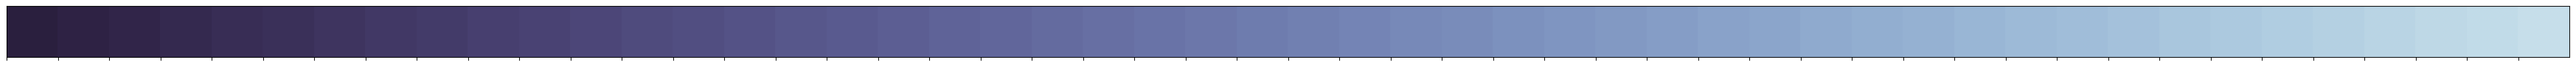

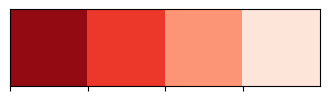

In [ ]:
number_of_owns = 50
own_sboxes_index = range(1,number_of_owns+1)

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=number_of_owns) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=10)[::-3]
sns.palplot(COLORS_FOR_OWNS)
sns.palplot(COLORS_FOR_CLASICS)

In [ ]:
to_proof = ["ascon", "fides_5_AB", "APN5"]
specs_clasics = []

for sbox_link in to_proof:
    sbox = load_sbox(f"data/clasics/{sbox_link}.json")
    specs_clasics.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs_clasics) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: ASCON (5x5)
Procesando S-Box: FIDES_5 (5x5)
Procesando S-Box: APN 5 (5x5)


In [ ]:
specs_owns = []

for i in own_sboxes_index:

    with open(f"data/5x5_sboxes/sbox_5_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
    
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"
            
        sbox = SBox(n_in, n_out, table, name)                    
        specs_owns.append({
            "name": name,              
            "table": data["best"],
            "n_in": n_in,
            "n_out": n_out,
            "color": COLORS_FOR_OWNS[len(specs_owns) % len(COLORS_FOR_OWNS)],
            "sbox":  sbox
        })

print(f"{len(specs_owns)} S-Boxes cargadas desde data.json")


50 S-Boxes cargadas desde data.json


In [ ]:

specs = specs_clasics + specs_owns

import matplotlib.colors as mcolors
for spec in specs:
    spec['color'] = mcolors.to_hex(spec['color'])

In [16]:
chart_tv = compare_tv_distance_altair(
    specs,
    r_values=list(range(1,16)),
    log_scale=True,
    detail=False
)
chart_tv

ValueError: invalid literal for int() with base 10: '0x4'

In [17]:
chart_mp = compare_max_probability_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=False,
    detail=True
)
chart_mp

|   r |     APN 5 |     ASCON |   FIDES_5 |   Variant #1 |   Variant #10 |   Variant #11 |   Variant #12 |   Variant #13 |   Variant #14 |   Variant #15 |   Variant #16 |   Variant #17 |   Variant #18 |   Variant #19 |   Variant #2 |   Variant #20 |   Variant #21 |   Variant #22 |   Variant #23 |   Variant #24 |   Variant #25 |   Variant #26 |   Variant #27 |   Variant #28 |   Variant #29 |   Variant #3 |   Variant #30 |   Variant #31 |   Variant #32 |   Variant #33 |   Variant #34 |   Variant #35 |   Variant #36 |   Variant #37 |   Variant #38 |   Variant #39 |   Variant #4 |   Variant #40 |   Variant #41 |   Variant #42 |   Variant #43 |   Variant #44 |   Variant #45 |   Variant #46 |   Variant #47 |   Variant #48 |   Variant #49 |   Variant #5 |   Variant #50 |   Variant #6 |   Variant #7 |   Variant #8 |   Variant #9 |
|----:|----------:|----------:|----------:|-------------:|--------------:|--------------:|--------------:|--------------:|--------------:|--------------:|-----------

alt.Chart(...)

In [18]:
chart_mix = compare_mixing_times_altair(
    specs,
    epsilons=[10**(-i) for i in range(3,11)],
    max_steps=10000,
)
chart_mix

[0.001, 0.0001, 1e-05, 1e-06, 1e-07, 1e-08, 1e-09, 1e-10]


alt.Chart(...)

In [19]:
chart_spec = compare_mixing_times_spectrals_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,11)],
    max_steps=10000,
)
chart_spec

alt.Chart(...)

# Clasicas

In [20]:
from evaluation.sbox_metrics_analysis import run_all_metrics

# Define specs (como ya haces) y tus valores de no-linealidad:
non_linearities = [12, 14, 16, 16]  # valores que tú determines
run_all_metrics(specs, non_linearities)

ValueError: invalid literal for int() with base 10: np.str_('0x1')

# Ranking

In [ ]:
import pandas as pd

# Carga el resumen de métricas generado por run_all_metrics
df = pd.read_csv('sbox_metrics_summary.csv')

# Calcula desviación de avg_sac respecto a 0.5 (ideal SAC = 0.5)
df['sac_error'] = (df['avg_sac'] - 0.5).abs()

# Genera rankings individuales (menor es mejor salvo non_linearity)
df['r_uniformity']    = df['uniformity'].rank(ascending=True)
df['r_max_ddt']       = df['max_ddt'].rank(ascending=True)
df['r_fixed_points']  = df['fixed_points'].rank(ascending=True)
df['r_non_linearity'] = df['non_linearity'].rank(ascending=False)
df['r_sac_error']     = df['sac_error'].rank(ascending=True)
df['r_max_std_sac']   = df['max_std_sac'].rank(ascending=True)

# Suma de rangos como puntaje agregado
rank_cols = ['r_uniformity','r_max_ddt','r_fixed_points',
             'r_non_linearity','r_sac_error','r_max_std_sac']
df['total_rank'] = df[rank_cols].sum(axis=1)

# Ordena y muestra top 5
top5 = df.sort_values('total_rank').reset_index(drop=True)
to_display = top5[['name','total_rank','non_linearity','uniformity',
                   'fixed_points','avg_sac','max_ddt','max_std_sac']].head(5)

import ace_tools as tools; tools.display_dataframe_to_user(name="Top 5 S-Boxes por puntaje agregado", dataframe=to_display)


In [ ]:

from evaluation.markov_chains.basic_markov_chain import create_transition_matrix  # tu función
import numpy as np

import pandas as pd
from neurokit2 import markov_mixingtime

def compute_neurokit_mixing_time(sbox_table, n_in, n_out):
    P = create_transition_matrix(np.array(sbox_table), n_in, n_out)
    assert np.allclose(P.sum(axis=1), 1), "Matriz de transición inválida"

    # Crear índice y columnas etiquetadas para DataFrame
    states = [f"{i}" for i in range(P.shape[0])]
    tm = pd.DataFrame(P, index=states, columns=states)

    tau = markov_mixingtime(tm)
    return tau


for spec in specs:
    tau = compute_neurokit_mixing_time(spec['table'], spec['n_in'], spec['n_out'])
    print(f"{spec['name']}: Mixing time (NeuroKit) = {tau:.4f}")


ASCON: Mixing time (NeuroKit) = 1.5844
FIDES_5: Mixing time (NeuroKit) = 1.2147
APN 5: Mixing time (NeuroKit) = 1.2446
Variant #0: Mixing time (NeuroKit) = 1.2455
Variant #1: Mixing time (NeuroKit) = 1.2454
Variant #2: Mixing time (NeuroKit) = 1.2873
Variant #3: Mixing time (NeuroKit) = 1.1951
Variant #4: Mixing time (NeuroKit) = 1.1833
Variant #5: Mixing time (NeuroKit) = 1.2892
Variant #6: Mixing time (NeuroKit) = 1.2850
Variant #7: Mixing time (NeuroKit) = 1.2078
Variant #8: Mixing time (NeuroKit) = 1.2248
